In [18]:
# loading event streams
import numpy as np
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt


normal_files = sorted(
    Path("dataset/Normal_Videos_003-_944").glob("*.npz")
)

fighting_files = sorted(
    Path("dataset/Abuse-Fighting/Fighting").glob("*.npz")
)

print(f"Found {len(normal_files)} normal videos")
print(f"Found {len(fighting_files)} fighting videos")

sample_normal = np.load(normal_files[0])

print(sample_normal.files)

for k in sample_normal.files:
    print(k, sample_normal[k].shape, sample_normal[k].dtype)



Found 158 normal videos
Found 53 fighting videos
['t', 'x', 'y', 'p']
t (6308606,) int64
x (6308606,) uint16
y (6308606,) uint16
p (6308606,) int16


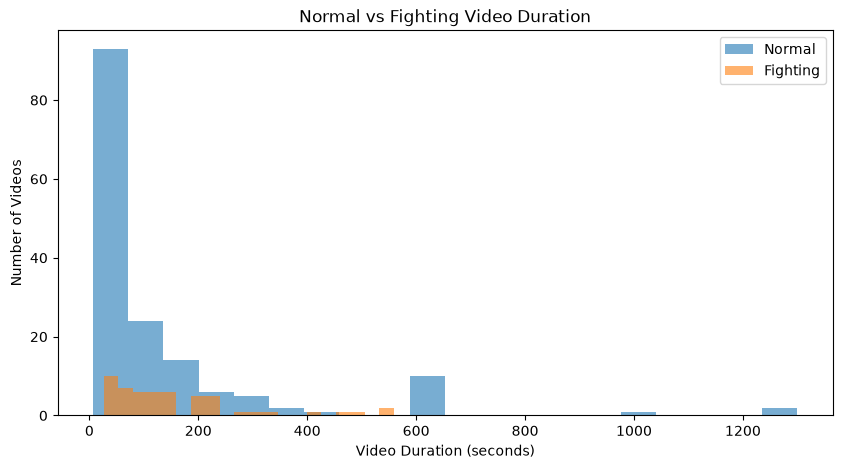

In [38]:
# normal video duration distribution
import numpy as np
import matplotlib.pyplot as plt

normal_durations = []
fighting_durations = []

# Normal
for f in normal_files:
    d = np.load(f)

    duration = (
        d["t"][-1] - d["t"][0]
    ) / 1e6

    normal_durations.append(duration)

# Fighting
for f in fighting_files:
    d = np.load(f)

    duration = (
        d["t"][-1] - d["t"][0]
    ) / 1e6

    fighting_durations.append(duration)

# Plot
plt.figure(figsize=(10,5))

plt.hist(
    normal_durations,
    bins=20,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    fighting_durations,
    bins=20,
    alpha=0.6,
    label="Fighting"
)

plt.xlabel("Video Duration (seconds)")
plt.ylabel("Number of Videos")
plt.title("Normal vs Fighting Video Duration")
plt.legend()

plt.show()

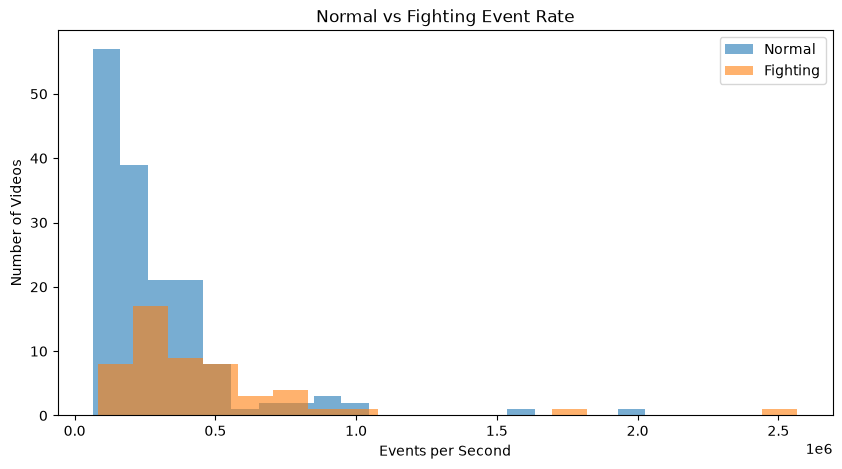

In [39]:
# event rate plots - fighting, normal
normal_rates = []
fighting_rates = []

for f in normal_files:
    d = np.load(f)

    duration = (d["t"][-1] - d["t"][0]) / 1e6

    normal_rates.append(
        len(d["t"]) / duration
    )

for f in fighting_files:
    d = np.load(f)

    duration = (d["t"][-1] - d["t"][0]) / 1e6

    fighting_rates.append(
        len(d["t"]) / duration
    )

plt.figure(figsize=(10,5))

plt.hist(normal_rates, bins=20, alpha=0.6,
         label="Normal")

plt.hist(fighting_rates, bins=20, alpha=0.6,
         label="Fighting")

plt.xlabel("Events per Second")
plt.ylabel("Number of Videos")
plt.title("Normal vs Fighting Event Rate")
plt.legend()

plt.show() 


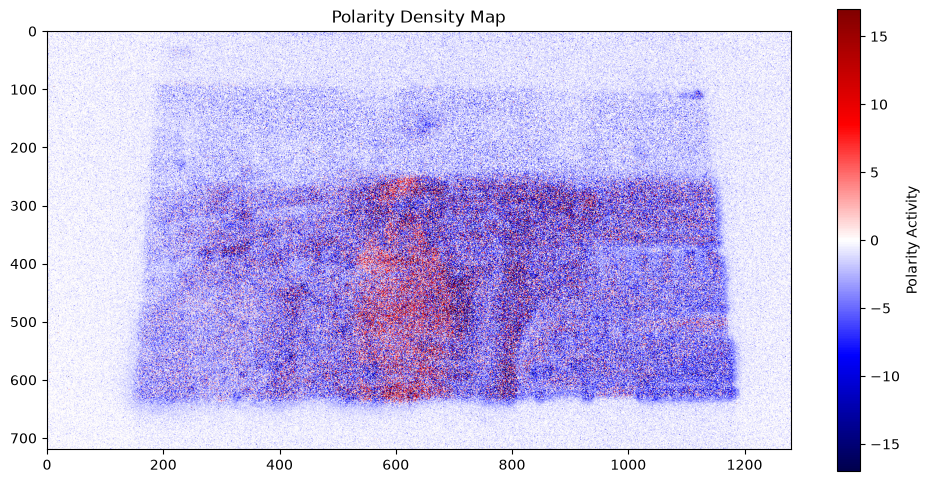

In [40]:
# polar density map for normal event
sample_normal = np.load(normal_files[40])
p_vis = np.where(sample_normal["p"] == 0, -1, 1)
density = np.zeros((720, 1280), dtype=np.float32)

np.add.at(
    density,
    (sample_normal["y"], sample_normal["x"]),
    p_vis
)

plt.figure(figsize=(12,6))

v = np.percentile(np.abs(density), 99)

plt.imshow(
    density,
    cmap="seismic",
    vmin=-v,
    vmax=v
)

plt.colorbar(label="Polarity Activity")
plt.title("Polarity Density Map")

plt.show()


In [41]:
from tonic.transforms import ToFrame
import numpy as np


def convert_to_frames_animate(data, time_window=100000):
    events = np.zeros(
        len(data["x"]),
        dtype=[
            ("x", np.int16),
            ("y", np.int16),
            ("t", np.int64),
            ("p", np.bool_)
        ]
    )

    events["x"] = data["x"]
    events["y"] = data["y"]
    events["t"] = data["t"]
    events["p"] = data["p"]

    frame_transform = ToFrame(
        sensor_size=(1280, 720, 2),
        time_window=time_window
    )

    return frame_transform(events)

In [42]:
from matplotlib import pyplot as plt, animation
from IPython.display import HTML
import numpy as np


def animate_frames(frames, fps=20):

    if frames.ndim == 4:
        frames = frames.sum(axis=1)       

    fig, ax = plt.subplots()
    ax.axis("off")

    img = ax.imshow(
        frames[0],
        cmap="gray",                      
        vmin=0,
        vmax=np.percentile(frames[frames > 0], 99) if (frames > 0).any() else 1
    )

    def update(i):
        img.set_data(frames[i])
        return [img]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=len(frames),
        interval=1000/fps
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())

In [43]:

sample_normal_frames = convert_to_frames_animate(np.load(fighting_files[6]))

animate_frames(sample_normal_frames[300:])

Animation size has reached 21048146 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


In [2]:
from sklearn.model_selection import train_test_split
RANDOM_STATE = 42

train_files, temp_files = train_test_split(
    normal_files,
    test_size=0.3,
    random_state=RANDOM_STATE
)

val_files, test_normal_files = train_test_split(
    temp_files,
    test_size=0.5,
    random_state=RANDOM_STATE
)

test_fighting_files = fighting_files

<!-- Doing a smokescreen test to verify pipeline -->

In [3]:
# baseline CNNae
import torch.nn as nn

class ConvAE(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(2, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, 2, stride=2),
            nn.ReLU(),

            nn.ConvTranspose2d(16, 2, 2, stride=2),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

In [6]:
from tonic.transforms import ToFrame
import numpy as np

def convert_to_frames(data, size=(64, 64), time_window=50000):

    H, W = size

    events = np.zeros(
        len(data["x"]),
        dtype=[
            ("x", np.int16),
            ("y", np.int16),
            ("t", np.int64),
            ("p", np.bool_)
        ]
    )

    # spatial downsampling BEFORE framing
    # cast to int32 first: x is stored as uint16, and x * 64 overflows it
    events["x"] = (data["x"].astype(np.int32) * W // 1280).astype(np.int16)
    events["y"] = (data["y"].astype(np.int32) * H // 720).astype(np.int16)

    assert events["x"].min() >= 0 and events["x"].max() < W
    assert events["y"].min() >= 0 and events["y"].max() < H

    events["t"] = data["t"]
    events["p"] = data["p"]

    frame_transform = ToFrame(
        sensor_size=(W, H, 2),
        time_window=time_window
    )

    frames = frame_transform(events)

    frames = np.log1p(frames.astype(np.float32))

    return frames

c:\Users\user\Desktop\SNN_anomaly_detection\venv313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
def process_split(files, out_dir, split_name):

    for i, file in enumerate(files):

        frames = convert_to_frames(
            np.load(file)
        ).astype(np.float16)

        np.save(f"{out_dir}/{file.stem}.npy", frames)     # was: {i}.npy

        print(
            f"{split_name}: "
            f"{i+1}/{len(files)}"
        )

In [8]:
from pathlib import Path
import shutil
shutil.rmtree("processed", ignore_errors=True)
# then re-run the mkdir cell and the process_split cell

Path("processed/train").mkdir(parents=True, exist_ok=True)
Path("processed/val").mkdir(parents=True, exist_ok=True)
Path("processed/test_normal").mkdir(parents=True, exist_ok=True)
Path("processed/test_fighting").mkdir(parents=True, exist_ok=True)
process_split(
    train_files,
    "processed/train",
    "Train"
)

process_split(
    val_files,
    "processed/val",
    "Val"
)

process_split(
    test_normal_files,
    "processed/test_normal",
    "Test Normal"
)

process_split(
    test_fighting_files,
    "processed/test_fighting",
    "Test Fighting"
)


Train: 1/110
Train: 2/110
Train: 3/110
Train: 4/110
Train: 5/110
Train: 6/110
Train: 7/110
Train: 8/110
Train: 9/110
Train: 10/110
Train: 11/110
Train: 12/110
Train: 13/110
Train: 14/110
Train: 15/110
Train: 16/110
Train: 17/110
Train: 18/110
Train: 19/110
Train: 20/110
Train: 21/110
Train: 22/110
Train: 23/110
Train: 24/110
Train: 25/110
Train: 26/110
Train: 27/110
Train: 28/110
Train: 29/110
Train: 30/110
Train: 31/110
Train: 32/110
Train: 33/110
Train: 34/110
Train: 35/110
Train: 36/110
Train: 37/110
Train: 38/110
Train: 39/110
Train: 40/110
Train: 41/110
Train: 42/110
Train: 43/110
Train: 44/110
Train: 45/110
Train: 46/110
Train: 47/110
Train: 48/110
Train: 49/110
Train: 50/110
Train: 51/110
Train: 52/110
Train: 53/110
Train: 54/110
Train: 55/110
Train: 56/110
Train: 57/110
Train: 58/110
Train: 59/110
Train: 60/110
Train: 61/110
Train: 62/110
Train: 63/110
Train: 64/110
Train: 65/110
Train: 66/110
Train: 67/110
Train: 68/110
Train: 69/110
Train: 70/110
Train: 71/110
Train: 72/110
T

In [9]:
class EventFrameDataset(Dataset):

    def __init__(self, folder, norm=1.0):          # new arg
        self.norm = norm
        self.files = sorted(Path(folder).glob("*.npy"))

        self.data = []
        for file in self.files:
            self.data.append(np.load(file, mmap_mode="r"))

        self.samples = []
        for file_idx, arr in enumerate(self.data):
            for frame_idx in range(len(arr)):
                self.samples.append((file_idx, frame_idx))

        self.video_ids = np.array([s[0] for s in self.samples])   # new

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        file_idx, frame_idx = self.samples[idx]
        frame = self.data[file_idx][frame_idx]
        frame = torch.from_numpy(frame.astype(np.float32)) / self.norm   # new
        return frame.clamp(0, 1)                                         # new

In [10]:
from torch.utils.data import DataLoader

def create_loaders(batch_size=64, norm=1.0):

    train_loader = DataLoader(
        EventFrameDataset("processed/train",norm),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        EventFrameDataset("processed/val",norm),
        batch_size=batch_size,
        shuffle=False
    )

    test_normal_loader = DataLoader(
        EventFrameDataset("processed/test_normal",norm),
        batch_size=batch_size,
        shuffle=False
    )

    test_fighting_loader = DataLoader(
        EventFrameDataset("processed/test_fighting",norm),
        batch_size=batch_size,
        shuffle=False
    )

    return (
        train_loader,
        val_loader,
        test_normal_loader,
        test_fighting_loader
    )

In [11]:
s = np.concatenate([np.load(f, mmap_mode="r")[::20]
                    for f in sorted(Path("processed/train").glob("*.npy"))[:30]]).astype(np.float32)
NORM = float(np.percentile(s[s > 0], 99.5))
print("NORM:", NORM, "| fraction clipped:", (s > NORM).mean())

(train_loader, val_loader, test_normal_loader, test_fighting_loader) = create_loaders(norm=NORM)

print(len(train_loader.dataset))
print(len(val_loader.dataset))
print(len(test_normal_loader.dataset))
print(len(test_fighting_loader.dataset))

NORM: 4.6328125 | fraction clipped: 0.0015436985049962762
310690
69196
50564
171797


In [12]:
def train_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    loss_sum = 0

    for batch_idx, x in enumerate(loader):

        if batch_idx % 500 == 0:
            print(
                f"Batch {batch_idx}/{len(loader)}"
            )

        x = x.to(device)

        optimizer.zero_grad()

        recon = model(x)

        loss = criterion(recon, x)

        loss.backward()

        optimizer.step()

        loss_sum += loss.item()

    return loss_sum / len(loader)

In [13]:
def evaluate_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    loss_sum = 0

    with torch.no_grad():

        for x in loader:

            x = x.to(device)

            recon = model(x)

            loss_sum += criterion(
                recon,
                x
            ).item()

    return loss_sum / len(loader)

In [14]:
import time

def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    epochs,
    device
):

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        start = time.time()

        train_loss = train_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss = evaluate_epoch(
            model,
            val_loader,
            criterion,
            device
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train={train_loss:.6f} | "
            f"Val={val_loss:.6f} | "
            f"Time={time.time()-start:.1f}s"
        )

    return train_losses, val_losses

In [15]:
def reconstruction_errors(
    model,
    loader,
    device
):

    model.eval()

    errors = []

    with torch.no_grad():

        for x in loader:

            x = x.to(device)

            recon = model(x)

            error = (
                (x - recon) ** 2
            ).mean(
                dim=(1,2,3)
            )

            errors.extend(
                error.cpu().numpy()
            )

    return np.array(errors)

In [16]:
from sklearn.metrics import roc_auc_score

def compute_auc(
    normal_errors,
    anomaly_errors
):

    y_true = (
        [0] * len(normal_errors)
        + [1] * len(anomaly_errors)
    )

    scores = (
        list(normal_errors)
        + list(anomaly_errors)
    )

    return roc_auc_score(
        y_true,
        scores
    )

In [ ]:
# full pipeline

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)


# model
model = ConvAE().to(device)

# Loss
criterion = nn.MSELoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

train_losses, val_losses = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    epochs=20,
    device=device
)



cuda
Batch 0/4855
Batch 500/4855
Batch 1000/4855
Batch 1500/4855
Batch 2000/4855
Batch 2500/4855
Batch 3000/4855
Batch 3500/4855
Batch 4000/4855
Batch 4500/4855
Epoch 1/20 | Train=0.009437 | Val=0.006403 | Time=127.5s
Batch 0/4855
Batch 500/4855
Batch 1000/4855
Batch 1500/4855
Batch 2000/4855
Batch 2500/4855
Batch 3000/4855
Batch 3500/4855
Batch 4000/4855
Batch 4500/4855
Epoch 2/20 | Train=0.006059 | Val=0.005955 | Time=53.7s
Batch 0/4855
Batch 500/4855
Batch 1000/4855
Batch 1500/4855
Batch 2000/4855
Batch 2500/4855
Batch 3000/4855
Batch 3500/4855
Batch 4000/4855
Batch 4500/4855
Epoch 3/20 | Train=0.005765 | Val=0.005757 | Time=52.1s
Batch 0/4855
Batch 500/4855
Batch 1000/4855
Batch 1500/4855
Batch 2000/4855
Batch 2500/4855
Batch 3000/4855
Batch 3500/4855
Batch 4000/4855
Batch 4500/4855
Epoch 4/20 | Train=0.005611 | Val=0.005633 | Time=52.1s
Batch 0/4855
Batch 500/4855
Batch 1000/4855
Batch 1500/4855
Batch 2000/4855
Batch 2500/4855
Batch 3000/4855
Batch 3500/4855
Batch 4000/4855
Batch 

NameError: name 'plt' is not defined

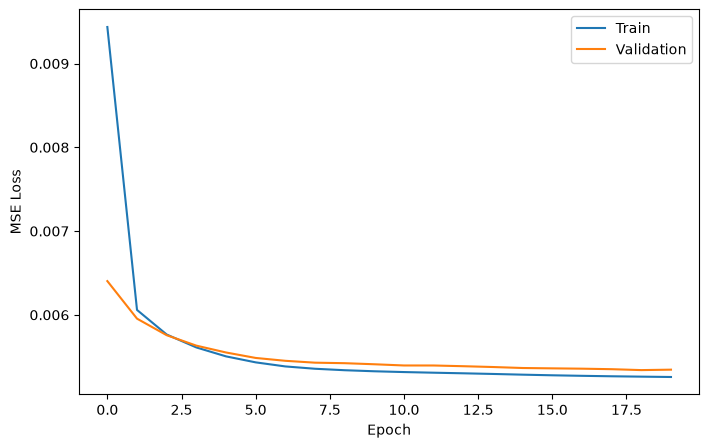

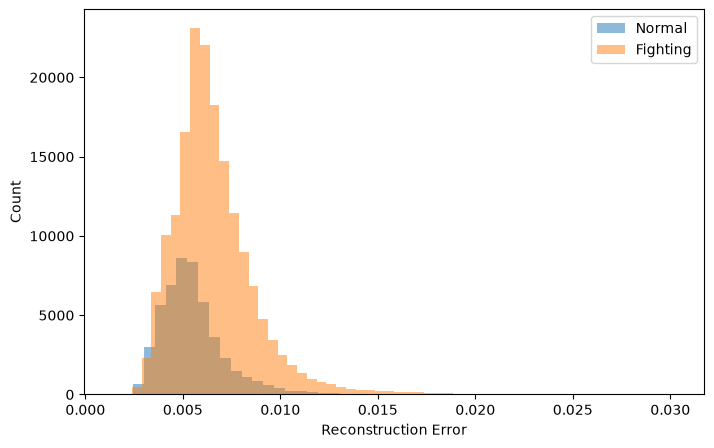

In [19]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()

plt.show()




normal_errors = reconstruction_errors(
    model,
    test_normal_loader,
    device
)

fighting_errors = reconstruction_errors(
    model,
    test_fighting_loader,
    device
)

plt.figure(figsize=(8,5))

plt.hist(
    normal_errors,
    bins=50,
    alpha=0.5,
    label="Normal"
)

plt.hist(
    fighting_errors,
    bins=50,
    alpha=0.5,
    label="Fighting"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Count")
plt.legend()

plt.show()

In [20]:
auc = compute_auc(
    normal_errors,
    fighting_errors
)

print(
    f"AUROC = {auc:.4f}"
)

AUROC = 0.6717


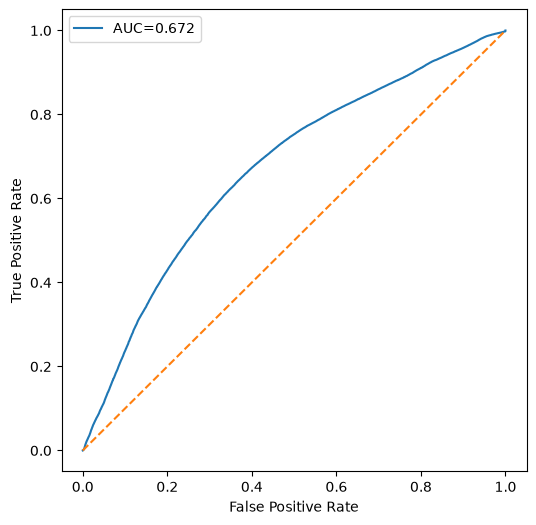

In [21]:
from sklearn.metrics import roc_curve

y_true = (
    [0] * len(normal_errors)
    + [1] * len(fighting_errors)
)

scores = (
    list(normal_errors)
    + list(fighting_errors)
)

fpr, tpr, _ = roc_curve(
    y_true,
    scores
)

plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC={auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

In [22]:
def video_scores(errors, video_ids, k=20):
    return np.array([np.sort(errors[video_ids == v])[-k:].mean()
                     for v in np.unique(video_ids)])

vn = video_scores(normal_errors,   test_normal_loader.dataset.video_ids)
vf = video_scores(fighting_errors, test_fighting_loader.dataset.video_ids)
print("Video-level AUROC:", compute_auc(vn, vf))

# baseline: raw events/sec per test video, no model
def rate(f):
    d = np.load(f)
    return len(d["t"]) / ((d["t"][-1] - d["t"][0]) / 1e6)

rn = [rate(f) for f in test_normal_files]
rf = [rate(f) for f in test_fighting_files]
print("Event-rate baseline AUROC:", compute_auc(rn, rf))

Video-level AUROC: 0.7028301886792453
Event-rate baseline AUROC: 0.6816037735849056
